# Motivation：VLM 输入 × 机器人速度 × DVFS

**问题背景**：机器人上只跑一个 VLM（Qwen2.5-VL-3B，Q4_K_M，Jetson Orin NX 16GB），没有其他应用。

- **任务给定的输入**：图像分辨率、图片数、文本长度，以及机器人能动作之前需要的输出 token 数 `n_act`。
- **任务 / 规划器给定的量**：速度 v。
- **我们能控制的**：只有 DVFS，即 CPU × GPU 频率。

这个 notebook 只用已有的测量数据回答一个问题：**我们的 objective 应该是什么，数据能不能支撑它。**

**数据**：
- `data/vlm_matrix.csv`：4 种分辨率 × 3 种图片数 × 3 种文本长度，在 3 个 CPU 频率 × 7 个 GPU 频率上测，外加默认 governor。每个配置重复 5 次，共 3960 个请求。
- `data/vlm_matrix_idle.csv`：每个频率点的空闲功率。
- 由 `vlm_bench.py` 测得。

**符号**：
- L_q(n)：前 n 个输出 token 完成时间的 p95，即 TTA(n) 的 p95。
- v*：满足安全约束的最大速度（定义见 Obs 4）。

In [168]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import plot_style; plot_style.apply()            # Times New Roman 16 pt; 2 panels (8,4), 3 panels (15,4)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA = Path("data")
df = pd.read_csv(DATA / "vlm_matrix.csv")
idle = pd.read_csv(DATA / "vlm_matrix_idle.csv")
df["res"] = df.res_w.astype(str) + "x" + df.res_h.astype(str)
df["inp"] = df.res + " x" + df.n_img.astype(str) + " t" + df.n_txt_target.astype(str)

# safety / task parameters (assumptions, same defaults as vlm_speed_requirements.py)
D, A_BRAKE, T_ACT, MARGIN, Q = 5.0, 2.0, 0.05, 0.5, 0.95   # m, m/s^2, s, m, latency quantile
DQ = 2.0                                                    # event-triggered: one query per DQ metres
NACT = [8, 16, 32]
V = np.round(np.arange(0.25, 3.01, 0.25), 2)

INP = ["res_w", "res", "n_img", "n_txt_target", "inp"]
g = df.groupby(["cpu", "gpu"] + INP)
agg = g.median(numeric_only=True)
for n in NACT:
    agg[f"q_{n}"] = g[f"tta_{n}"].quantile(Q)
agg = agg.reset_index()


def v_star(tta_ms):
    T = np.asarray(tta_ms, float) / 1000 + T_ACT
    r = D - MARGIN
    return A_BRAKE * (-T + np.sqrt(T ** 2 + 2 * r / A_BRAKE))


for n in NACT:
    agg[f"v_{n}"] = v_star(agg[f"q_{n}"])
P_IDLE = idle.groupby(["cpu", "gpu"]).idle_w.median()
agg["p_idle"] = [P_IDLE.get((c, gq), np.nan) for c, gq in zip(agg.cpu, agg.gpu)]
gov = agg[(agg.cpu == 0) & (agg.gpu == 0)].set_index("inp")
fx = agg[agg.cpu > 0]
CPUS, GPUS = sorted(fx.cpu.unique()), sorted(fx.gpu.unique())
CMAX, GMAX = CPUS[-1], GPUS[-1]
top = fx[(fx.cpu == CMAX) & (fx.gpu == GMAX)].set_index("inp")
ORDER = top.sort_values("n_vis").index.tolist()
print(f"{len(df)} requests, {df.groupby(INP).ngroups} inputs, CPU {CPUS}, GPU {GPUS} MHz (+ stock governor)")

3960 requests, 36 inputs, CPU [np.int64(576), np.int64(1190), np.int64(1984)], GPU [np.int64(306), np.int64(408), np.int64(510), np.int64(612), np.int64(714), np.int64(816), np.int64(918)] MHz (+ stock governor)


## Obs 1：输入不同，TTFT 相差一个数量级以上，主要由视觉 token 数决定

Visual token: 6.02 ms/token
Text token:   1.75 ms/token
Ratio:        3.45x


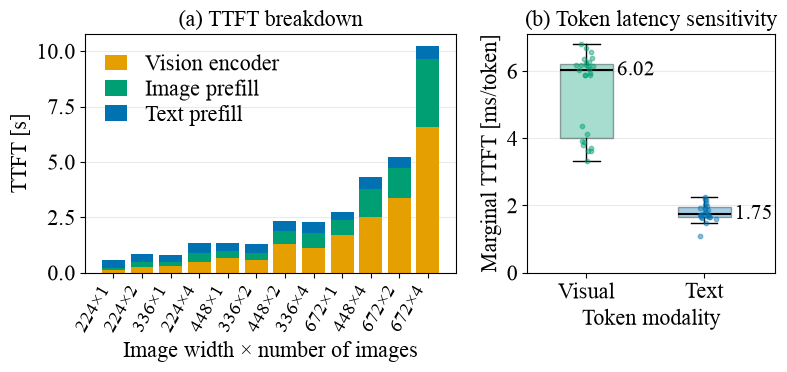

In [169]:

t = top.loc[ORDER].copy()

# ==========================================================
# 1. Marginal latency cost [ms/token]
# ==========================================================

vis_cost = []
txt_cost = []

# Visual token sensitivity:
# Fix text length and number of images.
for _, d in t.groupby(["n_txt_target", "n_img"]):
    d = d.sort_values("n_vis")

    dn = np.diff(d.n_vis.to_numpy())
    dt = np.diff(d.ttft.to_numpy())

    valid = dn > 0
    vis_cost.extend(dt[valid] / dn[valid])

# Text token sensitivity:
# Fix image resolution and number of images.
# Prefer actual text token count, if available.
txt_col = "n_txt" if "n_txt" in t.columns else "n_txt_target"

for _, d in t.groupby(["res_w", "n_img", "n_vis"]):
    d = d.sort_values(txt_col)

    dn = np.diff(d[txt_col].to_numpy())
    dt = np.diff(d.ttft.to_numpy())

    valid = dn > 0
    txt_cost.extend(dt[valid] / dn[valid])

vis_cost = np.asarray(vis_cost)
txt_cost = np.asarray(txt_cost)

vis_med = np.median(vis_cost)
txt_med = np.median(txt_cost)

print(f"Visual token: {vis_med:.2f} ms/token")
print(f"Text token:   {txt_med:.2f} ms/token")
print(f"Ratio:        {vis_med / txt_med:.2f}x")

# ==========================================================
# 2. Visualization
# ==========================================================

fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, gridspec_kw=dict(width_ratios=[1.5, 1])
)

# ----------------------------------------------------------
# (a) TTFT breakdown
# ----------------------------------------------------------

s = t[t.n_txt_target == 128].sort_values(
    ["n_vis", "res_w", "n_img"]
)

bottom = np.zeros(len(s))

stages = [
    ("t_enc",    "Vision encoder", "#E69F00"),
    ("t_img_pf", "Image prefill",  "#009E73"),
    ("t_txt_pf", "Text prefill",   "#0072B2")
]

for c, lab, color in stages:
    ax[0].bar(range(len(s)), s[c] / 1000, bottom=bottom, label=lab, color=color, width=0.8)
    bottom += s[c].to_numpy() / 1000

ax[0].set_xticks(range(len(s)), [f"{r.res_w}×{r.n_img}" for r in s.itertuples()], rotation=60, ha="right", fontsize=14)
ax[0].set(ylabel="TTFT [s]", xlabel="Image width × number of images", title="(a) TTFT breakdown")
ax[0].legend(frameon=False, labelspacing=.2, handlelength=1)

# ----------------------------------------------------------
# (b) Marginal token latency
# ----------------------------------------------------------

data = [vis_cost, txt_cost]
colors = ["#009E73", "#0072B2"]

bp = ax[1].boxplot(data, positions=[1, 2], widths=.45, patch_artist=True, showfliers=False,
    medianprops=dict(color="black", linewidth=1.5)
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(.35)

# Show individual measurements.
rng = np.random.default_rng(42)

for i, (values, color) in enumerate(zip(data, colors)):
    x = rng.normal(i + 1, .045, len(values))

    ax[1].scatter(x, values, s=10, color=color, alpha=.45, zorder=3)

    ax[1].annotate(
        f"{np.median(values):.2f}",
        (i + 1, np.median(values)),
        xytext=(22, 0),
        textcoords="offset points",
        va="center",
        fontsize=15
    )

ax[1].set_xticks([1, 2], ["Visual", "Text"])

ax[1].set(
    ylabel="Marginal TTFT [ms/token]",
    xlabel="Token modality",
    title="(b) Token latency sensitivity"
)

ax[1].set_xlim(.5, 2.6)
ax[1].set_ylim(bottom=0)

# ==========================================================
# 3. Figure settings
# ==========================================================

for a_ in ax:
    a_.set_axisbelow(True)
    a_.grid(axis="y", alpha=.25)

plt.tight_layout()
plt.savefig("paper/figs/vlm_token_cost.pdf", bbox_inches="tight", pad_inches=.01)
plt.show()


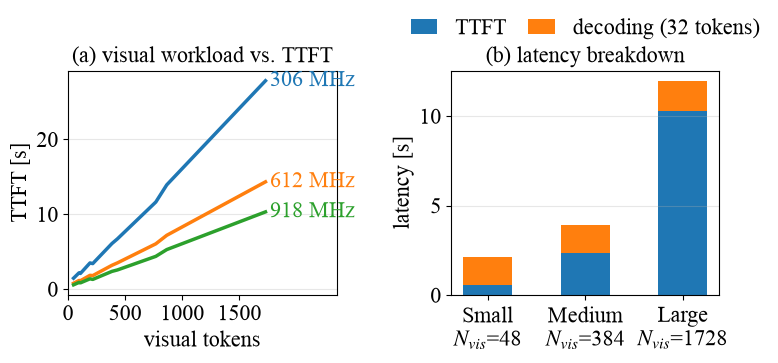

                 n_vis  TTFT_s  decode_s
inp                                     
224x168 x1 t128     48    0.56      1.56
448x336 x2 t128    384    2.36      1.57
672x504 x4 t128   1728   10.30      1.64


In [170]:
# (a) TTFT vs. visual tokens at three GPU clocks; (b) TTFT + decoding for small / medium / large inputs
TXT, NA = 128, 32                       # text length; output tokens before acting
d = fx[(fx.cpu == CMAX) & (fx.n_txt_target == TXT)]
fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2)
for gq, c in zip([306, 612, 918], ["tab:blue", "tab:orange", "tab:green"]):
    m = d[d.gpu == gq].groupby("n_vis").ttft.mean() / 1000
    ax[0].plot(m.index, m.values, "-", color=c, lw=2.5)
    ax[0].text(m.index[-1] + 40, m.values[-1], f"{gq} MHz", color=c, ha="left", va="center")
ax[0].set(xlabel="visual tokens", ylabel="TTFT [s]", title="(a) visual workload vs. TTFT", xlim=(0, 2350))
ax[0].set_xticks([0, 500, 1000, 1500])
ax[0].grid(axis="y", alpha=.3)

b = top[top.n_txt_target == TXT].sort_values("n_vis")
pick = b.iloc[[0, len(b) // 2, -1]]
ttft, dec = pick.ttft / 1000, (pick[f"tta_{NA}"] - pick.ttft) / 1000
xs = range(3)
ax[1].bar(xs, ttft, width=.5, label="TTFT")
ax[1].bar(xs, dec, width=.5, bottom=ttft, label=f"decoding ({NA} tokens)")
ax[1].set_xticks(xs, [f"{n}\n$N_{{vis}}$={v}" for n, v in zip(["Small", "Medium", "Large"], pick.n_vis.astype(int))])
ax[1].set(ylabel="latency [s]", title="(b) latency breakdown")
ax[1].grid(axis="y", alpha=.3)
ax[1].legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.1), ncol=2,
             columnspacing=1, handlelength=1.2, borderaxespad=0)
plt.tight_layout()
plt.savefig("paper/figs/obs1_workload_latency.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()
print(pd.DataFrame({"n_vis": pick.n_vis.astype(int), "TTFT_s": ttft.round(2), "decode_s": dec.round(2)}))

        a_ms   b_vis  c_txt  ratio  R2_split  R2_sum
gpu                                                 
306 -517.684  15.722  5.047  3.115     0.996   0.920
408 -373.757  11.942  3.841  3.109     0.997   0.920
510 -281.229   9.625  3.112  3.092     0.997   0.921
612 -222.727   8.069  2.607  3.095     0.997   0.921
714 -190.198   7.050  2.236  3.152     0.997   0.919
816 -159.844   6.298  1.978  3.185     0.996   0.918
918 -105.711   5.805  1.768  3.284     0.996   0.916
N_eff = N_vis + 0.32 * N_txt  (one visual token ~ 3.1 text tokens)


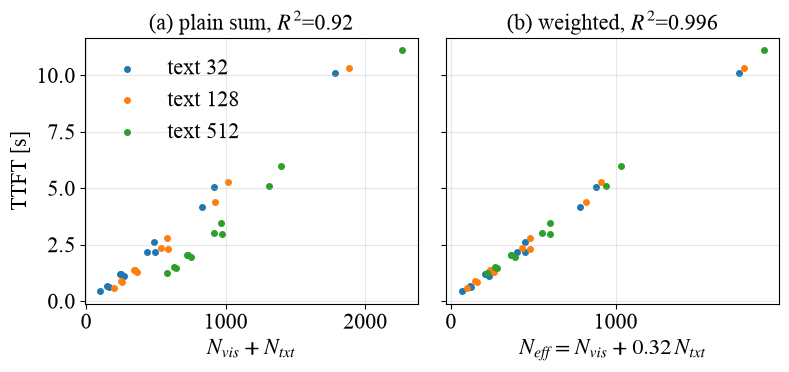

In [171]:
# vision vs. text tokens: TTFT = a + b*N_vis + c*N_txt; effective tokens N_eff = N_vis + (c/b)*N_txt
def r2(y, yh): return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()

rows = []
for gq in GPUS:
    d = fx[(fx.cpu == CMAX) & (fx.gpu == gq)]
    X = np.column_stack([np.ones(len(d)), d.n_vis, d.n_txt])
    (a, b, c), *_ = np.linalg.lstsq(X, d.ttft.values, rcond=None)
    s = d.n_vis + d.n_txt
    k1, a1 = np.polyfit(s, d.ttft, 1)
    rows.append(dict(gpu=gq, a_ms=a, b_vis=b, c_txt=c, ratio=b / c,
                     R2_split=r2(d.ttft.values, X @ [a, b, c]), R2_sum=r2(d.ttft.values, a1 + k1 * s.values)))
tok = pd.DataFrame(rows).set_index("gpu")
print(tok.round(3))
W = 1 / tok.ratio.median()                     # weight of one text token, in visual-token units
print(f"N_eff = N_vis + {W:.2f} * N_txt  (one visual token ~ {1 / W:.1f} text tokens)")

d = top.reset_index()
fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, sharey=True)
for k, g in d.groupby("n_txt_target"):
    ax[0].scatter(g.n_vis + g.n_txt, g.ttft / 1000, s=16, label=f"text {k}")
    ax[1].scatter(g.n_vis + W * g.n_txt, g.ttft / 1000, s=16)
ax[0].set(xlabel="$N_{vis}+N_{txt}$", ylabel="TTFT [s]",
          title=f"(a) plain sum, $R^2$={tok.loc[GMAX, 'R2_sum']:.2f}")
ax[1].set(xlabel=f"$N_{{eff}}=N_{{vis}}+{W:.2f}\\,N_{{txt}}$",
          title=f"(b) weighted, $R^2$={tok.loc[GMAX, 'R2_split']:.3f}")
for a_ in ax: a_.grid(alpha=.3)
ax[0].legend(frameon=False)
plt.tight_layout()
plt.savefig("paper/figs/obs1_effective_tokens.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

**视觉 token 和文本 token 不能直接相加**：
- 拟合 TTFT = a + b·N_vis + c·N_txt，R² ≈ 0.996；直接用 N_vis + N_txt，R² 只有 ≈ 0.92。
- 一个视觉 token 的成本约等于 3.1 个文本 token（918 MHz：5.8 对 1.8 ms/token），因为视觉 token 还要先过视觉编码器。这个比例在各个 GPU 频率下基本不变（3.1–3.3）。
- 所以可以用等效 token 数 N_eff = N_vis + 0.32·N_txt 作为输入大小的单一标量。同样 581 个 token，672×504 ×1 + t128 的 TTFT 是 2.8 s，224×168 ×1 + t512 只有 1.25 s。

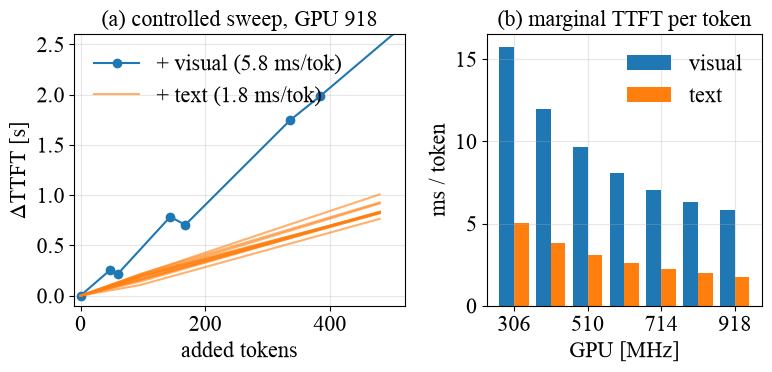

visual / text sensitivity ratio: 3.1 - 3.3x


In [172]:
# token sensitivity: how much TTFT grows per added visual vs. text token (uses `tok` from the cell above)
d = top.reset_index()
fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, gridspec_kw=dict(width_ratios=[1.2, 1]))
# (a) controlled sweeps at max clocks
v = d[d.n_txt_target == 32].groupby("n_vis").ttft.mean()            # vary images, text fixed at 32
ax[0].plot(v.index - v.index[0], (v - v.iloc[0]) / 1000, "o-", color="tab:blue", label=f"+ visual ({tok.loc[GMAX, 'b_vis']:.1f} ms/tok)")
for i, (k, g) in enumerate(d.groupby(["res_w", "n_img"])):           # vary text, image fixed
    g = g.sort_values("n_txt")
    ax[0].plot(g.n_txt - g.n_txt.iloc[0], (g.ttft - g.ttft.iloc[0]) / 1000, "-", color="tab:orange",
               alpha=.6, lw=1.5, label=f"+ text ({tok.loc[GMAX, 'c_txt']:.1f} ms/tok)" if i == 0 else None)
ax[0].set(xlabel="added tokens", ylabel=r"$\Delta$TTFT [s]", title=f"(a) controlled sweep, GPU {GMAX}",
          xlim=(-10, 520), ylim=(-0.1, 2.6))
ax[0].legend(frameon=False, loc="upper left")
# (b) marginal cost per token at every GPU clock
xg = np.arange(len(tok))
ax[1].bar(xg - .2, tok.b_vis, .4, color="tab:blue", label="visual")
ax[1].bar(xg + .2, tok.c_txt, .4, color="tab:orange", label="text")
ax[1].set_xticks(xg[::2], tok.index[::2])
ax[1].set(xlabel="GPU [MHz]", ylabel="ms / token", title="(b) marginal TTFT per token")
ax[1].legend(frameon=False)
for a_ in ax: a_.grid(alpha=.3)
plt.tight_layout()
plt.savefig("paper/figs/obs1_token_sensitivity.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()
print(f"visual / text sensitivity ratio: {tok.ratio.min():.1f} - {tok.ratio.max():.1f}x")

**结论**：
- 视觉部分（编码器加图像预填充）占了 TTFT 的大头。
- 分辨率 × 图片数，也就是视觉 token 数，基本决定了 TTFT。例如 224×168 × 4 图和 448×336 × 1 图都是 192 个视觉 token，TTFT 几乎一样。
- 文本长度是第二个因素：从 32 加到 512 token，多 0.6–1 s。
- **输入由任务决定，不能拿来优化，但它决定了延迟从哪里起步。**

## Obs 2：延迟 ≈ a + b / f_GPU，CPU 频率几乎没有影响

TTFT = a + b*1000/f fit: R2 min 0.995; GPU 306 -> 918 MHz speeds up TTFT x2.4 - x2.7
CPU 576 vs 1984 MHz at GPU 918: TTFT ratio 0.96 - 1.06


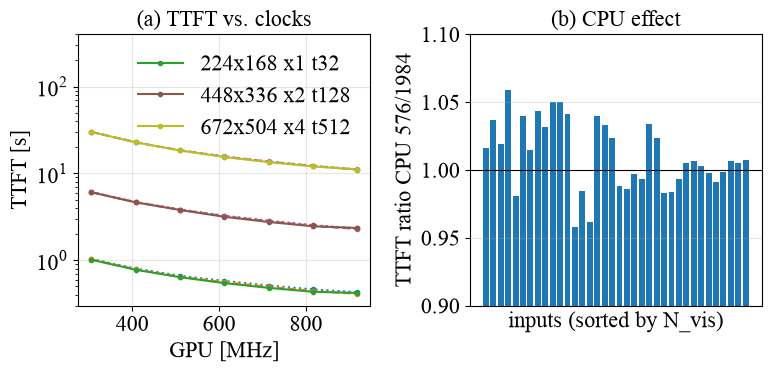

In [173]:
fits = []
for k, d in fx[fx.cpu == CMAX].groupby("inp"):
    x = 1000 / d.gpu.values
    b, a0 = np.polyfit(x, d.ttft.values, 1)
    fits.append(dict(inp=k, a=a0, b=b, R2=np.corrcoef(x, d.ttft)[0, 1] ** 2,
                     speedup=d.ttft.max() / d.ttft.min()))
fits = pd.DataFrame(fits).set_index("inp").loc[ORDER]
print(f"TTFT = a + b*1000/f fit: R2 min {fits.R2.min():.3f}; GPU 306 -> 918 MHz speeds up TTFT "
      f"x{fits.speedup.min():.1f} - x{fits.speedup.max():.1f}")
c = fx[fx.gpu == GMAX].pivot_table(index="inp", columns="cpu", values="ttft")
r = c[CPUS[0]] / c[CMAX]
print(f"CPU {CPUS[0]} vs {CMAX} MHz at GPU {GMAX}: TTFT ratio {r.min():.2f} - {r.max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2)
for k in [ORDER[0], ORDER[len(ORDER) // 2], ORDER[-1]]:
    for cpu, ls in zip(CPUS, [":", "--", "-"]):
        d = fx[(fx.inp == k) & (fx.cpu == cpu)]
        ax[0].plot(d.gpu, d.ttft / 1000, ls, marker="o", ms=3, label=k if cpu == CMAX else None)
ax[0].set(xlabel="GPU [MHz]", ylabel="TTFT [s]", yscale="log", ylim=(0.3, 400), title="(a) TTFT vs. clocks")
ax[0].legend(frameon=False)
ax[1].bar(range(len(r)), r.loc[ORDER].values)
ax[1].axhline(1, color="k", lw=.8)
ax[1].set(ylim=(0.9, 1.1), xticks=[], xlabel="inputs (sorted by N_vis)",
          ylabel=f"TTFT ratio CPU {CPUS[0]}/{CMAX}", title="(b) CPU effect")
for a_ in ax: a_.grid(alpha=.3)
plt.tight_layout()
plt.savefig("paper/figs/obs2_ttft_vs_clocks.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

**结论**：
- GPU 频率能把延迟调节约 2.4–2.7 倍，是唯一有效的"性能旋钮"。
- CPU 频率对延迟几乎没有影响，但会多耗功率（见 Obs 3）。所以 CPU 应该尽量放低。

## Obs 3：功率随频率变化：工作功率翻倍，空闲功率差 1.4 W，单次请求能耗在高 GPU 频率时最低

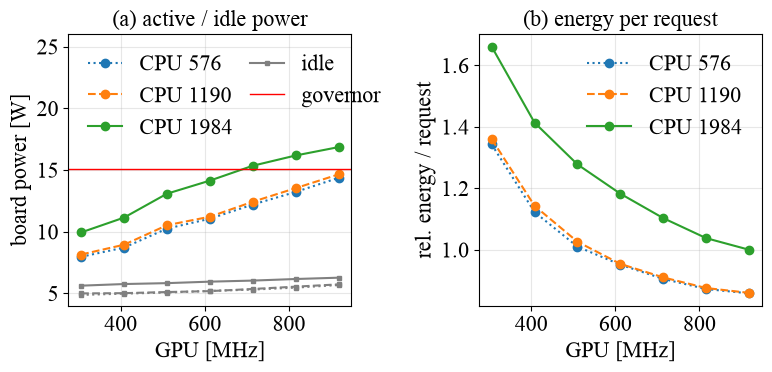

gpu   306   408   510   612   714   816   918
cpu                                          
576   8.0   8.7  10.3  11.1  12.2  13.2  14.4
1190  8.2   8.9  10.5  11.2  12.4  13.5  14.6
1984  9.9  11.1  13.1  14.1  15.3  16.2  16.9
energy per request relative to max clocks:
 gpu    306   408   510   612   714   816   918
cpu                                           
576   1.34  1.12  1.01  0.95  0.91  0.87  0.86
1190  1.36  1.14  1.03  0.95  0.91  0.88  0.86
1984  1.66  1.41  1.28  1.18  1.10  1.04  1.00


In [174]:
pw = fx.groupby(["cpu", "gpu"]).agg(mean_w=("mean_w", "median"), p_idle=("p_idle", "first")).reset_index()
fx = fx.assign(e_rel=fx.energy_8 / fx.inp.map(top.energy_8))
er = fx.groupby(["cpu", "gpu"]).e_rel.mean().reset_index()

fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2)
for cpu, ls in zip(CPUS, [":", "--", "-"]):
    d = pw[pw.cpu == cpu]
    ax[0].plot(d.gpu, d.mean_w, ls, marker="o", label=f"CPU {cpu}")
    ax[0].plot(d.gpu, d.p_idle, ls, marker="s", color="gray", ms=3, label="idle" if cpu == CMAX else None)
    e = er[er.cpu == cpu]
    ax[1].plot(e.gpu, e.e_rel, ls, marker="o", label=f"CPU {cpu}")
ax[0].axhline(gov.mean_w.median(), color="r", lw=1, label="governor")
ax[0].set(xlabel="GPU [MHz]", ylabel="board power [W]", ylim=(4, 26), title="(a) active / idle power")
ax[1].set(xlabel="GPU [MHz]", ylabel="rel. energy / request", title="(b) energy per request")
for a_ in ax: a_.grid(alpha=.3)
ax[0].legend(frameon=False, ncol=2, loc="upper left", columnspacing=.8, handlelength=1.5)
ax[1].legend(frameon=False)
plt.tight_layout()
plt.savefig("paper/figs/obs3_power_energy.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()
print(pw.pivot(index="cpu", columns="gpu", values="mean_w").round(1))
print("energy per request relative to max clocks:\n", er.pivot(index="cpu", columns="gpu", values="e_rel").round(2))

**结论**：功率的两种计法给出相反的最优点。
- **按平均功率**（VLM 一直在跑）：越低频越省，约 8 W 对 17 W。
- **按单次请求能耗**（跑完就空闲）：GPU 在高频时最低，因为跑得快、早结束；CPU 在 576 时最低。

所以 **objective 是"平均功率"还是"单次请求能耗"，取决于 VLM 怎么被调用**，两者的最优频率不同，必须在问题定义里写清楚。

## Obs 4：速度决定延迟上限，不同输入能支持的速度相差约 6 倍

**安全约束**：VLM 给出结果之前机器人继续前进，之后还要能在 D 米内刹停：

v·(L_q(n_act) + t_act) + v²/(2a) + margin ≤ D

**参数**：D = 5 m，a = 2 m/s²，t_act = 0.05 s，margin = 0.5 m。这些都是假设值。

反过来说，**速度 v 定了，延迟上限 τ(v) 也就定了**：τ(v) = (D − margin − v²/2a)/v − t_act。

latency budget tau(v) [s]: {0.25: 17.89, 0.5: 8.82, 1.0: 4.2, 1.5: 2.58, 2.0: 1.7, 3.0: 0.7}
v* (n_act=8) at max clocks: 0.39 - 2.77 m/s; at GPU 306: 0.14 - 1.80 m/s


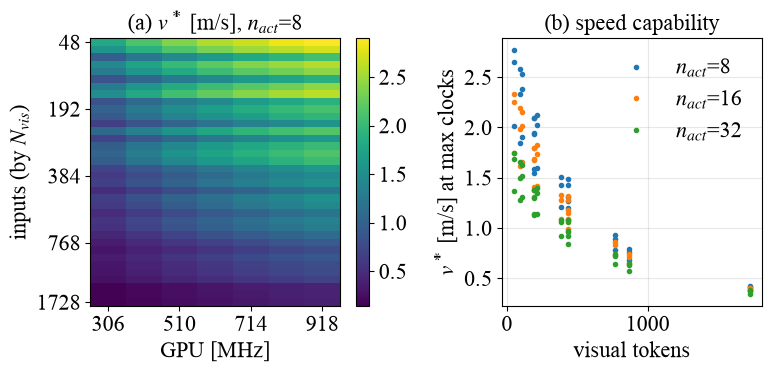

In [175]:
def tau(v):   # latency budget [s] implied by speed v
    v = np.asarray(v, float)
    return (D - MARGIN - v ** 2 / (2 * A_BRAKE)) / v - T_ACT


print("latency budget tau(v) [s]:", {float(v): round(float(tau(v)), 2) for v in [0.25, 0.5, 1, 1.5, 2, 3]})
best_cpu = fx.groupby(["inp", "gpu"]).v_8.max().unstack().loc[ORDER]
print(f"v* (n_act=8) at max clocks: {top.v_8.min():.2f} - {top.v_8.max():.2f} m/s; "
      f"at GPU {GPUS[0]}: {best_cpu[GPUS[0]].min():.2f} - {best_cpu[GPUS[0]].max():.2f} m/s")

fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, gridspec_kw=dict(width_ratios=[1.2, 1]))
im = ax[0].imshow(best_cpu.values, aspect="auto", cmap="viridis")
ax[0].set_xticks(range(len(GPUS))[::2], GPUS[::2])
YT = [0, 9, 18, 27, 35]
NV = top.loc[ORDER, "n_vis"].astype(int).values
ax[0].set_yticks(YT, [str(NV[i]) for i in YT])
ax[0].set(xlabel="GPU [MHz]", ylabel="inputs (by $N_{vis}$)", title="(a) $v^*$ [m/s], $n_{act}$=8")
plt.colorbar(im, ax=ax[0])
for n in NACT:
    ax[1].plot(top.loc[ORDER, "n_vis"], top.loc[ORDER, f"v_{n}"], "o", ms=3, label=f"$n_{{act}}$={n}")
ax[1].set(xlabel="visual tokens", ylabel="$v^*$ [m/s] at max clocks", title="(b) speed capability")
ax[1].grid(alpha=.3); ax[1].legend(frameon=False)
plt.tight_layout()
plt.savefig("paper/figs/obs4_speed_capability.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

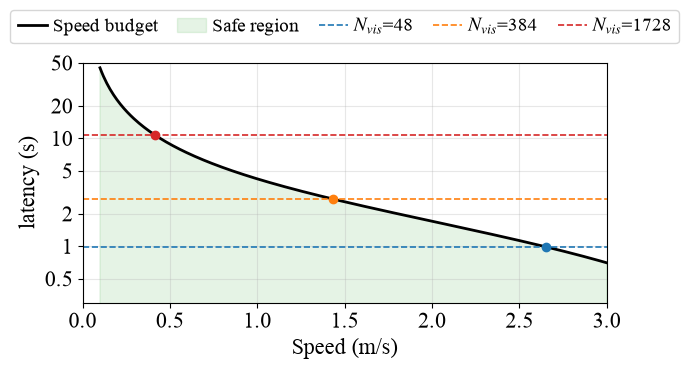

In [176]:
vv = np.linspace(0.1, 3.0, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vv, tau(vv), "k-", lw=2, label=r"Speed budget")
ax.fill_between(vv, 1e-2, tau(vv), color="tab:green", alpha=.12, label="Safe region")
t128 = top[top.n_txt_target == 128].sort_values("n_vis").index      # fix text length, vary visual input
for k, c in zip([t128[0], t128[len(t128) // 2], t128[-1]], ["tab:blue", "tab:orange", "tab:red"]):
    L = top.loc[k, "q_8"] / 1000
    vs = top.loc[k, "v_8"]
    ax.axhline(L, color=c, ls="--", lw=1.2, label=f"$N_{{vis}}$={int(top.loc[k, 'n_vis'])}")
    ax.plot(vs, L, "o", color=c, ms=6)
ax.set(xlabel="Speed (m/s)", ylabel="latency (s)", yscale="log", xlim=(0, 3), ylim=(0.3, 50))
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50], ["0.5", "1", "2", "5", "10", "20", "50"])
ax.minorticks_off()
ax.grid(alpha=.3)
ax.legend(ncol=5, loc='lower center', bbox_to_anchor=(0.50, 1.04), frameon=True, handletextpad=0.3, 
          columnspacing=1.0, fontsize=14, handlelength=1.5)
plt.tight_layout()
plt.savefig("paper/figs/obs4_speed_latency.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

**结论**：
- 安全约束把**速度和输入耦合**在一起：输入越大、n_act 越多，同样的速度就需要越高的 GPU 频率。
- 某些（输入，速度）组合，即使用最高频也不安全。这说明**速度本身就是一个硬上限**：v_max(输入) = v*(最高频)。

## Obs 5：默认 governor 不知道速度：高速时延迟不够，低速时又白白耗电

In [177]:
gv = gov.loc[ORDER]
print(f"stock governor under load: CPU {gv.cpu_mean.median():.0f} MHz, GPU {gv.gpu_mean.median():.0f} MHz (median);"
      f" power {gv.mean_w.min():.1f}-{gv.mean_w.max():.1f} W vs {top.mean_w.min():.1f}-{top.mean_w.max():.1f} W at max clocks")
print(f"governor TTFT / max-clock TTFT: {(gv.ttft / top.loc[ORDER].ttft).min():.2f} - {(gv.ttft / top.loc[ORDER].ttft).max():.2f}")
rows = []
for v in V:
    feas_max = top.v_8 >= v
    feas_gov = gv.v_8 >= v
    if feas_max.sum():
        rows.append(dict(v=v, feasible_at_max=int(feas_max.sum()),
                         governor_misses=int((feas_max & ~feas_gov.reindex(feas_max.index)).sum())))
print(pd.DataFrame(rows).set_index("v").T)

stock governor under load: CPU 1238 MHz, GPU 882 MHz (median); power 13.7-16.4 W vs 15.8-17.8 W at max clocks
governor TTFT / max-clock TTFT: 1.03 - 1.47
v                0.25  0.50  0.75  1.00  1.25  1.50  1.75  2.00  2.25  2.50  2.75
feasible_at_max    36    33    32    27    24    19    15    11     6     4     1
governor_misses     0     0     1     0     2     4     3     5     3     3     1


**结论**：
- 默认 governor 在 VLM 负载下基本把 GPU 拉到接近最高频，功率接近最高频时的水平，但延迟又比最高频长。
- 低速时它不需要这么快，白白耗电。高速时，一些最高频本来能满足的（输入，速度）组合，它反而达不到。
- 它**既不知道输入，也不知道速度**。这就是我们要解决的问题。

## Obs 6：最优频率同时取决于输入和速度，任何固定设置都不够

两种调用方式下的平均功率（VLM 在 n_act 个 token 后停止）：
- **连续查询（A）**：请求一个接一个，平均功率 P̄_A(f) = E_req(f) / L(f)。约束只有安全约束 v_n(f) ≥ v。
- **事件触发（B）**：每走 dq 米查询一次，周期 T_q = dq / v。平均功率 P̄_B(f) = [E_req(f) + P_idle(f)·(T_q − L(f))] / T_q。约束是 v_n(f) ≥ v 且 L_q(f) ≤ T_q。

**比较的策略**（都只在最高频能满足约束的（输入，速度）组合上比较）：
- `max`：固定 1984/918 MHz。
- `governor`：默认调频。
- `speed-only`：只知道速度，每个速度选一个频率，要对最坏的输入也满足约束。
- `input-only`：只知道输入，每个输入选一个频率，要对最高可行速度也满足约束。
- `oracle`：同时知道输入和速度。

In [178]:
N = 8


def cost(rows, v, mode):
    # average power [W] of every DVFS row for speed v; NaN if infeasible
    L, E = rows[f"tta_{N}"].values / 1000, rows[f"energy_{N}"].values
    ok = rows[f"v_{N}"].values >= v
    if mode == "A":
        return np.where(ok, E / L, np.nan)
    Tq = DQ / v
    ok &= rows[f"q_{N}"].values / 1000 <= Tq
    return np.where(ok, (E + rows.p_idle.values * (Tq - L)) / Tq, np.nan)


def policies(mode):
    tab = {}                                  # (inp, v) -> cost per DVFS point
    pts = list(fx.groupby(["cpu", "gpu"]).groups)
    for k, d in fx.groupby("inp"):
        d = d.set_index(["cpu", "gpu"]).loc[pts].reset_index()
        for v in V:
            c = cost(d, v, mode)
            if not np.isnan(c[pts.index((CMAX, GMAX))]):
                tab[(k, v)] = c
    T = pd.DataFrame(tab, index=pd.MultiIndex.from_tuples(pts)).T     # rows (inp, v), cols DVFS
    res = pd.DataFrame(index=T.index)
    res["max"] = T[(CMAX, GMAX)]
    res["governor"] = [float(cost(gov.loc[[k]], v, mode)[0]) for k, v in T.index]
    res["oracle"] = T.min(axis=1)
    res["oracle_gpu"] = [pts[int(np.nanargmin(r))][1] for r in T.values]
    # one point per speed: must be feasible for every input at that speed -> min of the column sums
    for name, lvl in [("speed-only", 1), ("input-only", 0)]:
        best = {}
        for key, sub in T.groupby(level=lvl):
            allok = sub.notna().all()
            best[key] = sub.loc[:, allok].sum().idxmin() if allok.any() else None
        res[name] = [T.loc[(k, v), best[(k, v)[lvl]]] if best[(k, v)[lvl]] else np.nan for k, v in T.index]
    return res


summ = {}
for mode in ["A", "B"]:
    R = policies(mode)
    globals()[f"R_{mode}"] = R
    m = R[["max", "governor", "input-only", "speed-only", "oracle"]].mean()
    summ[f"mode {mode}"] = pd.concat([m.round(2), (100 * (1 - m / m["max"])).round(1).add_prefix("saving% ")])
print(f"mean average power [W] over feasible (input, v) points, n_act={N}, dq={DQ} m")
print(pd.DataFrame(summ))

mean average power [W] over feasible (input, v) points, n_act=8, dq=2.0 m
                    mode A  mode B
max                  14.89   10.99
governor             13.14    9.61
input-only           11.88    9.40
speed-only           11.63    9.52
oracle                9.16    8.97
saving% max           0.00    0.00
saving% governor     11.80   12.60
saving% input-only   20.20   14.50
saving% speed-only   21.90   13.40
saving% oracle       38.50   18.40


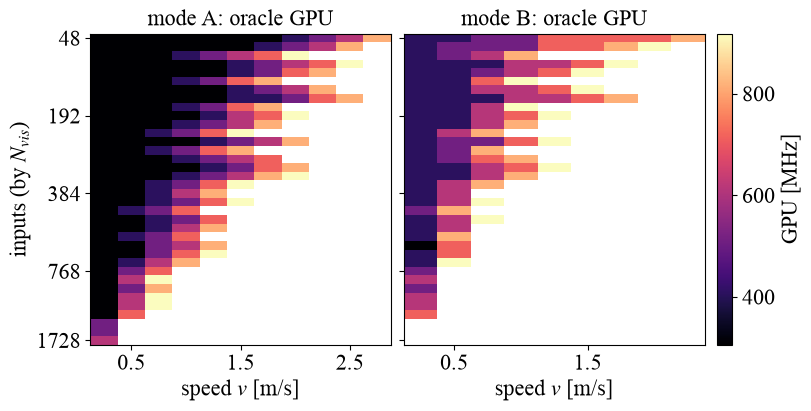

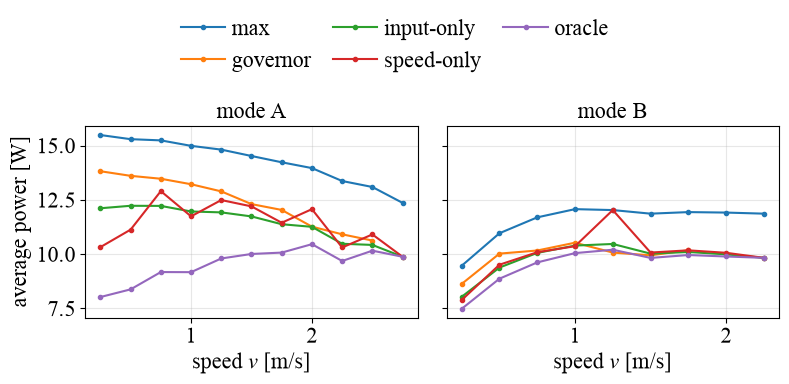

In [179]:
fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, sharey=True, layout="constrained")
for a_, mode in zip(ax, "AB"):
    R = globals()[f"R_{mode}"]
    hm = R.oracle_gpu.unstack().reindex(ORDER)
    im = a_.imshow(hm.values, aspect="auto", cmap="magma", vmin=GPUS[0], vmax=GMAX)
    a_.set_xticks(range(hm.shape[1])[1::4], [f"{v:g}" for v in hm.columns][1::4])
    a_.set(xlabel="speed $v$ [m/s]", title=f"mode {mode}: oracle GPU")
ax[0].set_yticks(YT, [str(NV[i]) for i in YT]); ax[0].set_ylabel("inputs (by $N_{vis}$)")
fig.colorbar(im, ax=ax, fraction=.05, pad=.02).set_label("GPU [MHz]")
plt.savefig("paper/figs/obs6_oracle_gpu.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=plot_style.FIG2, sharey=True)
for a_, mode in zip(ax, "AB"):
    R = globals()[f"R_{mode}"]
    m = R.groupby(level=1)[["max", "governor", "input-only", "speed-only", "oracle"]].mean()
    for c in m:
        a_.plot(m.index, m[c], "o-", ms=3, label=c)
    a_.set(xlabel="speed $v$ [m/s]", title=f"mode {mode}")
    a_.grid(alpha=.3)
ax[0].set_ylabel("average power [W]")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, frameon=False, columnspacing=1, handletextpad=.3)
plt.tight_layout(rect=(0, 0, 1, .8))
plt.savefig("paper/figs/obs6_policy_power.pdf", bbox_inches="tight", pad_inches=0.01)
plt.show()

**结论**：
- 最优 GPU 频率在（输入，速度）平面上变化很大，没有一个固定设置能同时覆盖所有情况。
- 只看速度、或只看输入的策略，都必须按最坏情况选频率，节省的功率都比 oracle 少。
- **同时利用输入和速度信息**才能拿到全部收益。
- **两种调用方式的收益差别很大**（n_act=8，dq=2 m）：
  - 连续查询（A）：oracle 比最高频省约 38%，比默认 governor 省约 30%（9.2 W 对 13.1 W）。
  - 事件触发（B）：oracle 比最高频只省约 18%，比默认 governor 只省约 7%（9.0 W 对 9.6 W）。原因是大部分时间在空闲，空闲功率占了平均功率的大头。
  - 所以**连续查询是这个 objective 最有说服力的场景**。事件触发更适合作为"调用方式"这个维度的对比。
- 注意：默认 governor 的平均功率只算了它能满足约束的点，在高速时偏乐观。

## Obs 7：如果速度也能自由选，问题会退化

如果让速度也变成决策变量，目标改成**任务总计算能耗**（走完 S 米的计算能耗 = P̄·S/v），会怎样？下面算一下每个输入下最优的速度。

In [180]:
rows = []
for mode in "AB":
    R = globals()[f"R_{mode}"]
    jpm = (R.oracle / R.index.get_level_values(1)).rename("J_per_m")       # compute energy per metre
    for k, d in jpm.groupby(level=0):
        vbest = d.idxmin()[1]
        vmax = d.index.get_level_values(1).max()
        rows.append(dict(mode=mode, inp=k, v_best=vbest, v_max_feasible=vmax))
r = pd.DataFrame(rows)
for mode, d in r.groupby("mode"):
    print(f"mode {mode}: {(d.v_best == d.v_max_feasible).mean() * 100:.0f}% of inputs have "
          f"energy-optimal speed = fastest feasible speed")

mode A: 86% of inputs have energy-optimal speed = fastest feasible speed
mode B: 97% of inputs have energy-optimal speed = fastest feasible speed


**结论**：
- 把速度也放开时，计算能耗最低的速度绝大多数情况下（连续查询 86%，事件触发 97% 的输入）就是最高可行速度，对应的频率也接近最高频。也就是说，"跑得越快越省"，问题退化了。
- 再加上机械能耗、用之前的 P_mech 模型也一样会退化，这一点之前已经验证过。
- 所以把速度当作**任务给定**的量更合理，也更符合实际：速度由规划器根据路况、人流等决定。

## 可以作为 Objective 的几种定义

### O1（推荐）：同时利用输入和速度的 DVFS，计算能耗最小

**已知**：任务输入 x = (分辨率, 图片数, N_txt, n_act)，速度 v，D，查询方式（连续，或每 dq 米查询一次）。

min_{f ∈ F_CPU × F_GPU}  P̄(f; x, v)

约束：
- 安全：L_q(f; x, n_act) ≤ τ(v) = (D − margin − v²/2a)/v − t_act
- 事件触发时还要满足查询频率：L_q(f; x, n_act) ≤ T_q = dq / v

其中 P̄ 是平均功率：连续查询时 P̄ = E_req / L；事件触发时 P̄ = [E_req + P_idle(T_q − L)] / T_q。

**数据支撑**：
- Obs 1：输入让延迟相差一个数量级以上。
- Obs 2：GPU 频率是有效的旋钮，CPU 应该放低。
- Obs 3：连续查询和事件触发的最优点相反，必须指定调用方式。
- Obs 4：速度通过 τ(v) 给出延迟上限。
- Obs 5：默认 governor 两头都不好。
- Obs 6：oracle 比最高频和默认 governor 省得多，只看一个维度的策略省不全。
- Obs 7：v 必须是给定的，否则问题退化。

### O2（O1 的对偶）：给定功率预算，最大化安全速度

max_f v*(f; x)  s.t.  P̄(f; x) ≤ P_budget

适用场景：电池或散热限制了功率，规划器需要知道"当前输入下最快能开多快"。数据就是 Obs 4 的速度上限和 Obs 3 的功率曲线组成的 Pareto 前沿。

### O3（不推荐）：速度和频率一起优化，最小化任务总能耗

min_{v, f} P̄(f)·S/v（还可以加上机械能耗）。按 Obs 7，最优解会落在最高可行速度加接近最高频，没有研究价值，只适合作为说明"为什么要把速度当作给定量"的反例。

### 其他可选的方向
- **延迟分布**：现在用 p95，可以换成要求违反安全约束的概率 ≤ ε 的形式。
- **调用方式本身可以作为决策变量**：用 Obs 3 的数据比较连续查询和事件触发，以及查询间隔 dq 选多大。